In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

billboard = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-08-26/billboard.csv')
topics = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-08-26/topics.csv')


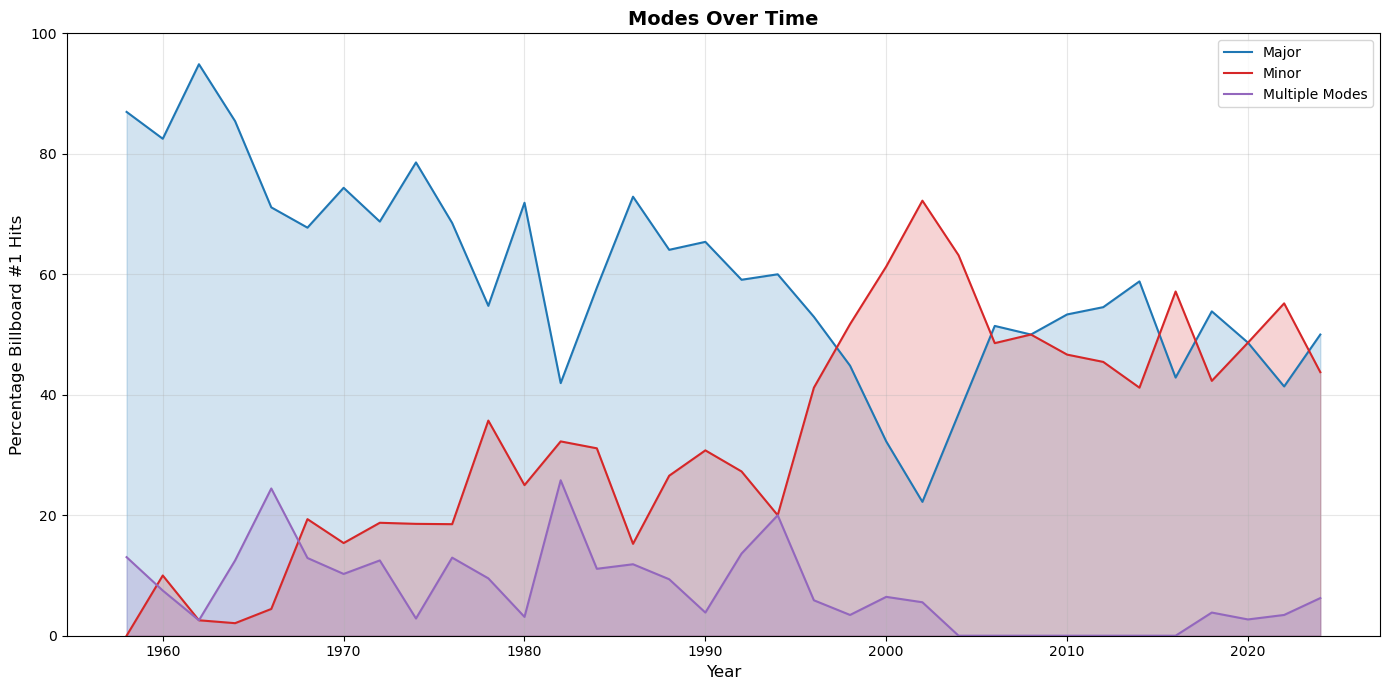

In [2]:
def assign_mode(key): #turning keys into major/minor/multiple keys
    if isinstance(key, str):
        if key == 'Multiple Keys':
            return 'Multiple Modes'
        elif key.endswith('m'):
            return 'Minor'
    return 'Major'

billboard['mode'] = billboard['simplified_key'].apply(assign_mode)
billboard['date'] = pd.to_datetime(billboard['date'])
billboard['year'] = billboard['date'].dt.year
billboard['year_bin'] = (billboard['year'] // 2) * 2 #binning by 2 years
mode_by_year = billboard.groupby(['year_bin', 'mode']).size().unstack(fill_value=0)

mode_pct = mode_by_year.div(mode_by_year.sum(axis=1), axis=0) * 100 #counting modes, turning them into percentages

fig, ax = plt.subplots(figsize=(14, 7)) #create line plot
colors = {'Major': '#1f77b4', 'Minor': '#d62728', 'Multiple Modes': '#9367bd'} #use old colors because new colors blend bad
mode_order = ['Major', 'Minor', 'Multiple Modes']
mode_pct = mode_pct[[col for col in mode_order if col in mode_pct.columns]]

for col in mode_order: 
    if col in mode_pct.columns:
        ax.plot(mode_pct.index, mode_pct[col], label=col, color=colors[col], alpha=1.0)

ax.fill_between(mode_pct.index, mode_pct['Major'], color="#1f77b4", alpha=0.2) #fill space under lines
ax.fill_between(mode_pct.index, mode_pct['Minor'], color="#d62728", alpha=0.2)
if 'Multiple Modes' in mode_pct.columns:
    ax.fill_between(mode_pct.index, mode_pct['Multiple Modes'], color="#9367bd", alpha=0.2)

ax.set_xlabel('Year', fontsize=12) #labeling things
ax.set_ylabel('Percentage Billboard #1 Hits', fontsize=12)
ax.set_title('Modes Over Time', fontsize=14, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()


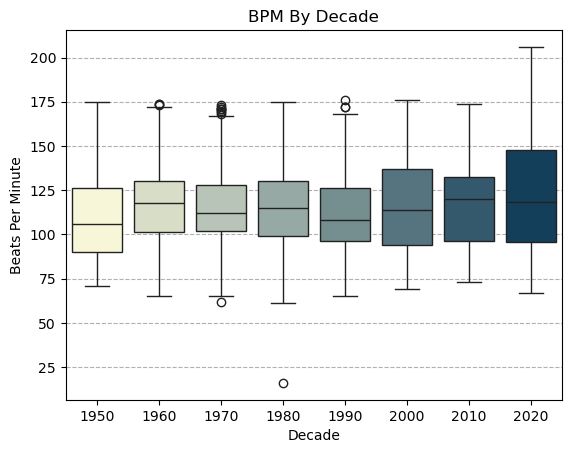

In [3]:
billboard['decade'] = (billboard['date'].dt.year // 10) * 10 
palette = sns.blend_palette(["#FDFBD4", "#084266"], n_colors=8) # build color palette from slideshow hex codes
ax = sns.boxplot(data = billboard, 
                x = "decade", 
                y = "bpm", 
                hue = "decade", 
                gap = 0.8, 
                width = 4.0, 
                legend = False, 
                palette = palette)
ax.set_title("BPM By Decade", fontsize = 12) #labeling
ax.set_ylabel("Beats Per Minute")
ax.set_xlabel("Decade")
ax.grid(True, axis = "y", linestyle = "--")

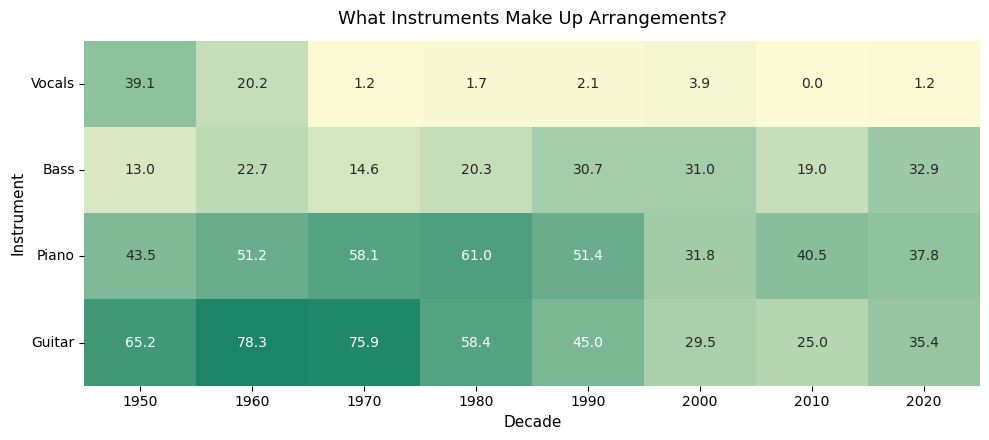

In [4]:
cols = [
    "vocally_based",
    "bass_based",
    "piano_keyboard_based",
    "guitar_based",
] #selecting columns

heatmap_data = billboard.groupby("decade")[cols].mean().mul(100).T
palette = sns.blend_palette(["#FDFBD4", "#1c8567"], n_colors=100) # recreate color palette but bigger

label_map = { #fix the y axis labels
    "vocally_based": "Vocals",
    "bass_based": "Bass",
    "piano_keyboard_based": "Piano",
    "guitar_based": "Guitar",
}
heatmap_data = heatmap_data.rename(index=label_map)

plt.figure(figsize=(10, 4.5)) #heat map
ax = sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap= palette,
    cbar = False,
    cbar_kws={"label": "% of Songs"},
)

ax.set_title("What Instruments Make Up Arrangements?", fontsize=13, pad=12) #labeling
ax.set_xlabel("Decade", fontsize=11)
ax.set_ylabel("Instrument", fontsize=11)
plt.yticks(rotation=0)  

plt.tight_layout()
plt.show()

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = [ #selecting columns for line plot
    "danceability",
    "energy",
    "happiness",
]

long_df = billboard.melt( #reshape the long way
    id_vars="five_year",
    value_vars=cols,
    var_name="feature",
    value_name="score",
)

long_df["feature"] = long_df["feature"].str.title() #capitalize features in legend

custom_colors = { #color palette
    "Danceability": "#1b9e77",
    "Energy": "#d95f02",
    "Happiness": "#7570b3",
}

plt.figure(figsize=(11, 5))
ax = sns.lineplot(
    data=long_df,
    x="five_year",
    y="score",
    hue="feature",
    palette=["#1c8567", "#084266", "#fe7f2d"], #color palette from slideshow
    errorbar=None,
)

ax.set_title("Song Descriptors Over Time", fontsize=13, pad=12) 
ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("Average Score", fontsize=11)
plt.legend(title="Feature")

plt.tight_layout()
plt.show()

KeyError: "The following id_vars or value_vars are not present in the DataFrame: ['five_year']"